In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/bank-full.csv")

In [ ]:
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [ ]:
df.shape

(45211, 17)

In [ ]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)
df.columns = df.columns.str.strip().str.lower()

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    df[col] = df[col].str.strip().str.lower()

In [ ]:
df['y'] = df['y'].map({'no': 0, 'yes': 1})

print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True) * 100)

y
0    39922
1     5289
Name: count, dtype: int64
y
0    88.30152
1    11.69848
Name: proportion, dtype: float64


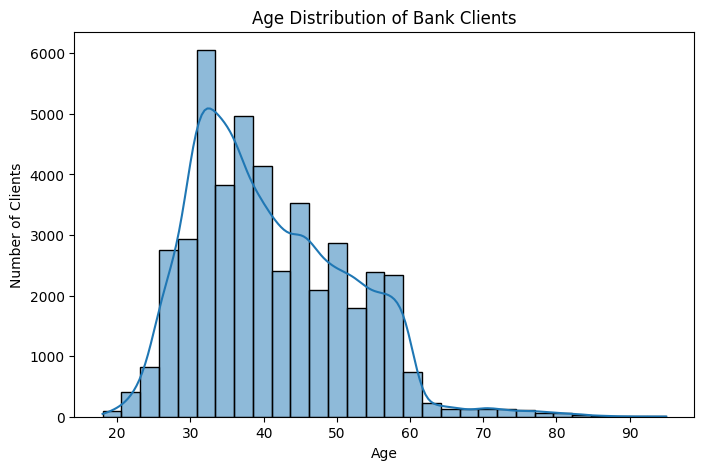

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64


In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=30, kde=True)
plt.title('Age Distribution of Bank Clients')
plt.xlabel('Age')
plt.ylabel('Number of Clients')
plt.show()

print(df['age'].describe())

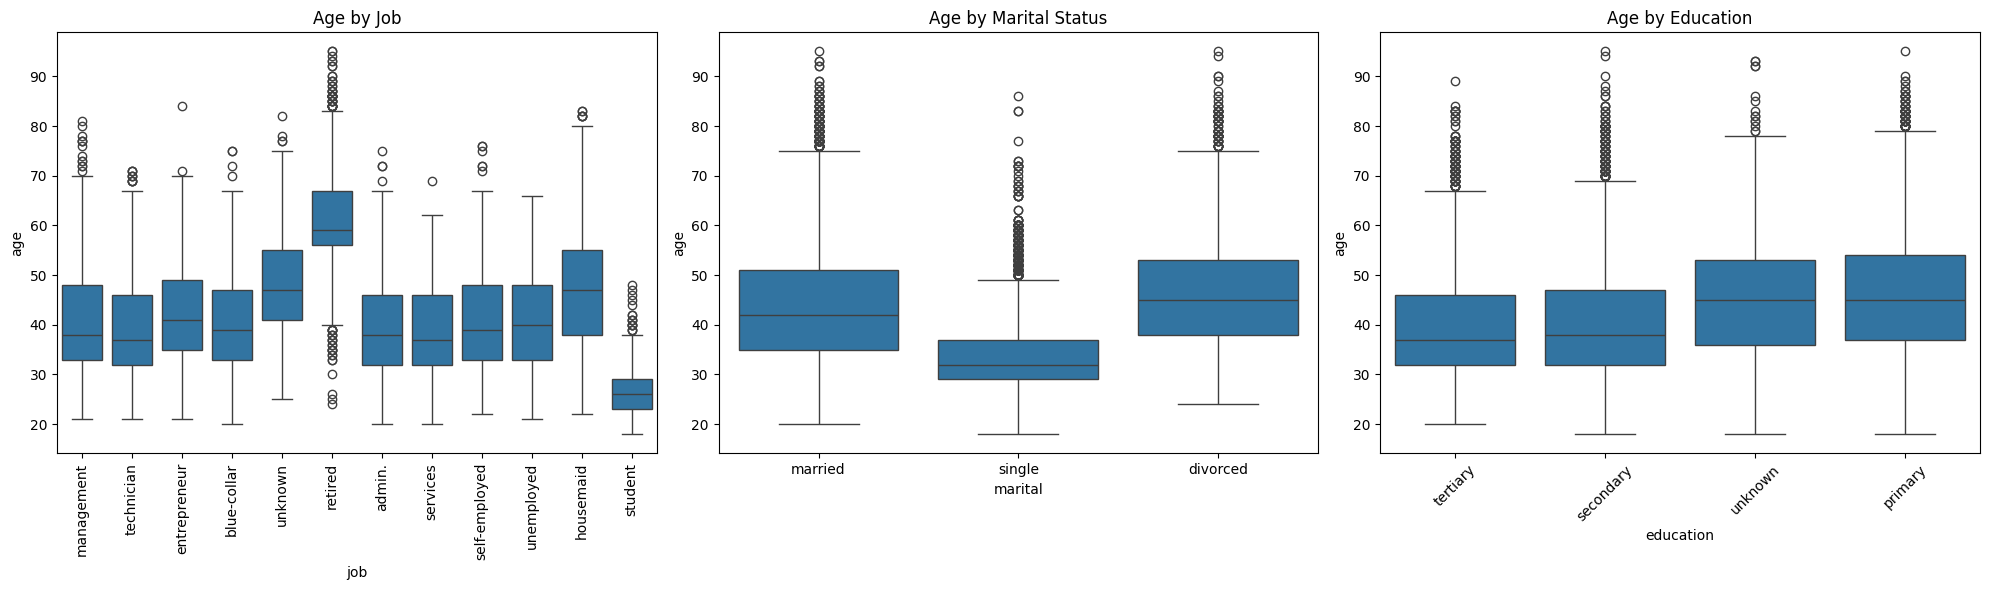

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.boxplot(data=df, x='job', y='age', ax=axes[0])
axes[0].set_title('Age by Job')
axes[0].tick_params(axis='x', rotation=90)

sns.boxplot(data=df, x='marital', y='age', ax=axes[1])
axes[1].set_title('Age by Marital Status')

sns.boxplot(data=df, x='education', y='age', ax=axes[2])
axes[2].set_title('Age by Education')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

loan        no   yes    All
housing                    
no       17204  2877  20081
yes      20763  4367  25130
All      37967  7244  45211


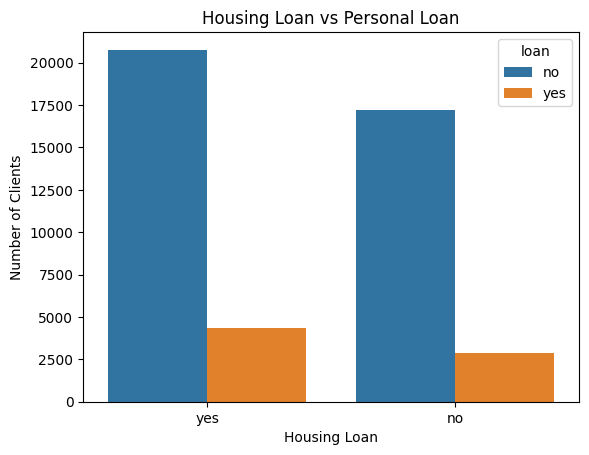

In [ ]:
loan_table = pd.crosstab(
    df['housing'],
    df['loan'],
    margins=True)

print(loan_table)

sns.countplot(data=df, x='housing', hue='loan')
plt.title('Housing Loan vs Personal Loan')
plt.xlabel('Housing Loan')
plt.ylabel('Number of Clients')
plt.show()

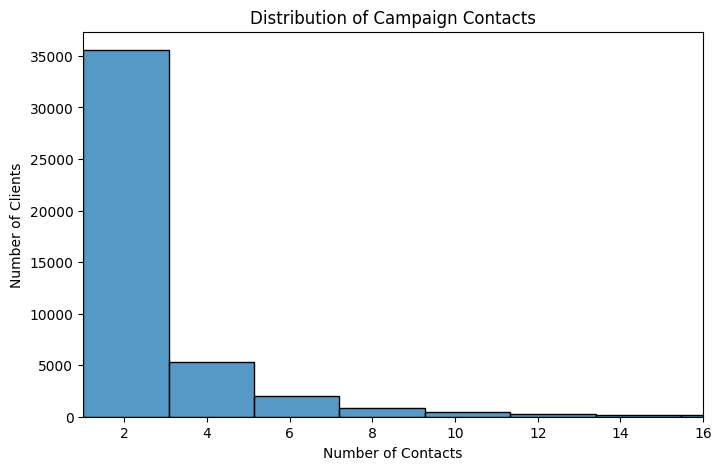

          clients  subscriptions  success_rate
campaign                                      
1           17544           2561     14.597583
2           12505           1401     11.203519
3            5521            618     11.193624
4            3522            317      9.000568
5            1764            139      7.879819
6            1291             92      7.126259
7             735             47      6.394558
8             540             32      5.925926
9             327             21      6.422018
10            266             14      5.263158
11            201             16      7.960199
12            155              4      2.580645
13            133              6      4.511278
14             93              4      4.301075
15             84              4      4.761905


In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['campaign'], bins=30)
plt.title('Distribution of Campaign Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel('Number of Clients')
plt.xlim(1, df['campaign'].quantile(0.99))
plt.show()

campaign_success = df.groupby('campaign')['y'].agg(
    clients='count',
    subscriptions='sum',
    success_rate='mean')

campaign_success['success_rate'] *= 100

print(campaign_success.head(15))

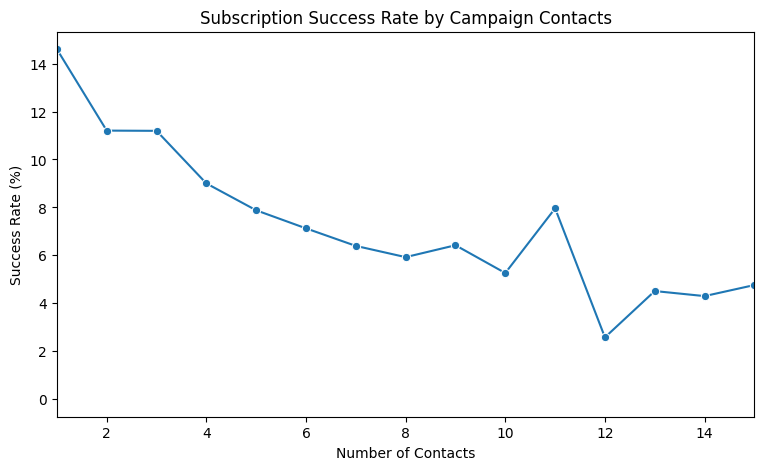

In [ ]:
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=campaign_success.reset_index(),
    x='campaign',
    y='success_rate',
    marker='o'
)
plt.title('Subscription Success Rate by Campaign Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel('Success Rate (%)')
plt.xlim(1, 15)
plt.show()

In [ ]:
from scipy.stats import ttest_ind, mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    classification_report, confusion_matrix,
    roc_auc_score)

In [ ]:
housing_yes = df.loc[df['housing'] == 'yes', 'balance']
housing_no = df.loc[df['housing'] == 'no', 'balance']

# Welch's t-test
t_stat, p_value = ttest_ind(
    housing_yes,
    housing_no,
    equal_var=False)

print("Mean balance (housing loan):", housing_yes.mean())
print("Mean balance (no housing loan):", housing_no.mean())
print("Welch t-statistic:", t_stat)
print("Welch p-value:", p_value)

if p_value < 0.05:
    print("Reject H0: The mean balances differ significantly.")
else:
    print("Fail to reject H0: Insufficient evidence of a mean difference.")

# Additional non-parametric test
u_stat, mw_p_value = mannwhitneyu(
    housing_yes,
    housing_no,
    alternative='two-sided')

print("Mann-Whitney p-value:", mw_p_value)

Mean balance (housing loan): 1175.1030640668523
Mean balance (no housing loan): 1596.5012698570788
Welch t-statistic: -14.081117553694206
Welch p-value: 6.625425926072512e-45
Reject H0: The mean balances differ significantly.
Mann-Whitney p-value: 8.96237974972647e-48


y           1.000000
duration    0.342469
previous    0.169124
pdays       0.154055
campaign   -0.084054
Name: y, dtype: float64


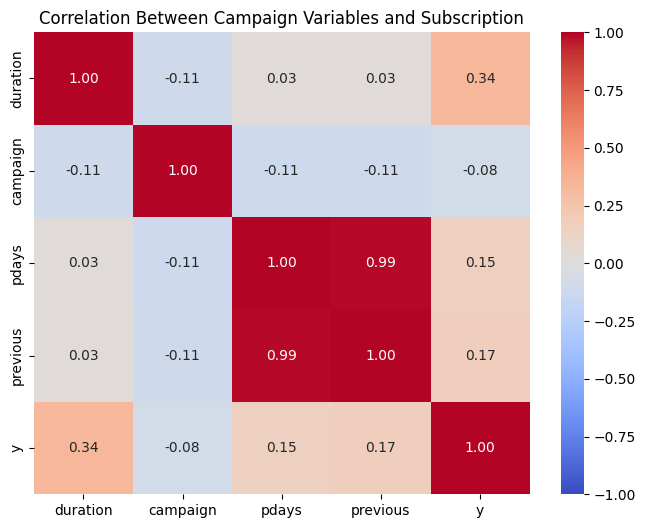

In [ ]:
campaign_cols = ['duration', 'campaign', 'pdays', 'previous', 'y']

correlation = df[campaign_cols].corr(method='spearman')

print(correlation['y'].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1)
plt.title('Correlation Between Campaign Variables and Subscription')
plt.show()

In [ ]:
X = df.drop(columns=['y', 'duration'])
y = df['y']

categorical_features = X.select_dtypes(
    include='object').columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number).columns.tolist()

# Preprocess numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numerical_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 36168
Testing records: 9043


In [ ]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

Accuracy: 0.893
Precision: 0.627
Recall: 0.213
ROC-AUC: 0.792

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.90      0.98      0.94      7985
   Subscription       0.63      0.21      0.32      1058

       accuracy                           0.89      9043
      macro avg       0.77      0.60      0.63      9043
   weighted avg       0.87      0.89      0.87      9043



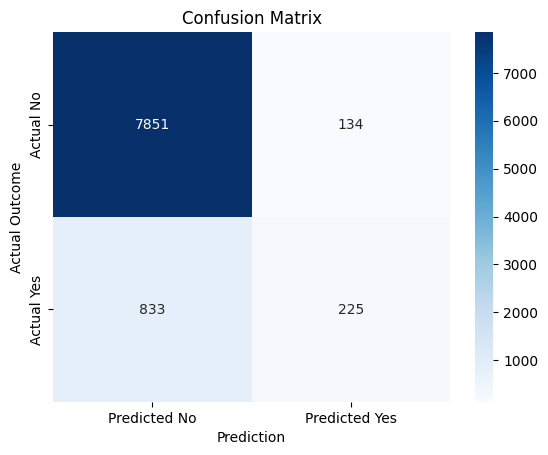

In [ ]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Subscription', 'Subscription'],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted No', 'Predicted Yes'],
    yticklabels=['Actual No', 'Actual Yes']
)

plt.title('Confusion Matrix')
plt.xlabel('Prediction')
plt.ylabel('Actual Outcome')
plt.show()